# 03 · Distribución espacial (Sprint 5 · Paso 3 - EDA)

Kernel: **Python (chicago-crimes)**.

**Objetivo:** dónde ocurre el crimen — por community area (ranking, arresto,
doméstico), la nube de coordenadas lat/lon, y el cruce tipo×área.

**Principio (plan §4 / AGENTS):** el ranking y el resumen por área vienen de
las **vistas del Sprint 4** (`vw_area_crime_ranking`, `vw_area_summary`);
las coordenadas y el cross-tab se consultan directo a `staging.crimes`.
PostgreSQL agrega, Python presenta.

> Insumo del mapa coroplético y del panel de hotspots del dashboard
> (Sprints 7 y 10).


In [1]:
# Setup: imports, conexión a dev (5432) y helper de query
from decimal import Decimal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

DB = dict(host="localhost", port=5432, user="postgres",
          password="postgres", dbname="chicago_crimes")
conn = psycopg2.connect(**DB)
# autocommit: cada SELECT es su propia transacción. Sin esto, una query
# fallida aborta la transacción compartida y TODAS las siguientes celdas
# fallan con InFailedSqlTransaction (y se pierde el error real).
conn.autocommit = True

def q(sql, params=None):
    """Query -> DataFrame (psycopg2 + pandas, sin SQLAlchemy).

    PG numeric (p.ej. round(...)) llega como Decimal; lo paso a float para
    que matplotlib pueda graficarlo (Decimal -> 'no numeric data to plot').
    """
    cur = conn.cursor()
    cur.execute(sql, params or ())
    cols = [d[0] for d in cur.description]
    out = pd.DataFrame(cur.fetchall(), columns=cols)
    cur.close()
    for c in out.columns:
        if out[c].map(lambda v: isinstance(v, Decimal)).any():
            out[c] = out[c].astype(float)
    return out

print("PostgreSQL", conn.info.server_version)


PostgreSQL 160015


## 1 · Ranking por community area — `vw_area_crime_ranking`

Top 15 áreas por volumen, con su share del total. (RANK con empates viene
resuelto en la vista.)


,community_area,community_area_name,crime_count,share_pct,crime_rank
0,25,Austin,927,4.7,1
1,8,Near North Side,871,4.4,2
2,28,Near West Side,845,4.3,3
3,43,South Shore,695,3.5,4
4,32,Loop,679,3.5,5
5,24,West Town,600,3.1,6
6,71,Auburn Gresham,571,2.9,7
7,69,Greater Grand Crossing,552,2.8,8
8,29,North Lawndale,487,2.5,9
9,23,Humboldt Park,477,2.4,10


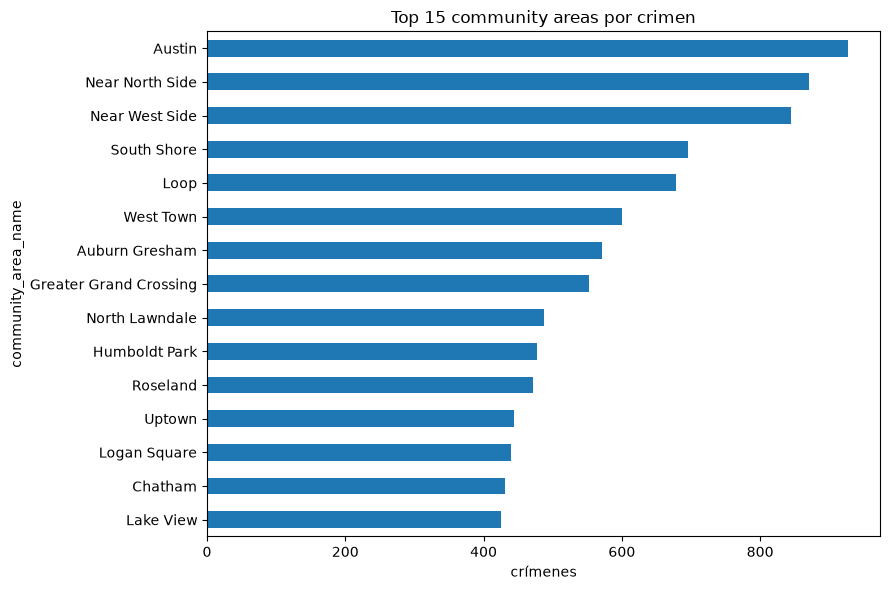

In [2]:
rank = q("""
SELECT community_area, community_area_name, crime_count, share_pct, crime_rank
FROM warehouse.vw_area_crime_ranking
ORDER BY crime_count DESC
LIMIT 15
""")
display(rank)

ax = rank.sort_values("crime_count").plot.barh(
    x="community_area_name", y="crime_count", figsize=(9, 6),
    title="Top 15 community areas por crimen", legend=False)
ax.set_xlabel("crímenes")
plt.tight_layout()


## 2 · Arresto y doméstico por área — `vw_area_summary`

Tasas calculadas en SQL sobre el resumen de la vista. Áreas con mucho crimen
pero bajo arresto = foco operativo.


,community_area_name,crime_count,arrest_pct,domestic_pct
0,Austin,927,16.4,28.0
1,Near North Side,871,12.4,5.4
2,Near West Side,845,9.8,9.9
3,South Shore,695,14.8,28.3
4,Loop,679,18.3,4.0
5,West Town,600,7.3,8.3
6,Auburn Gresham,571,16.5,34.7
7,Greater Grand Crossing,552,18.8,29.0
8,North Lawndale,487,23.4,25.5
9,Humboldt Park,477,18.9,19.1


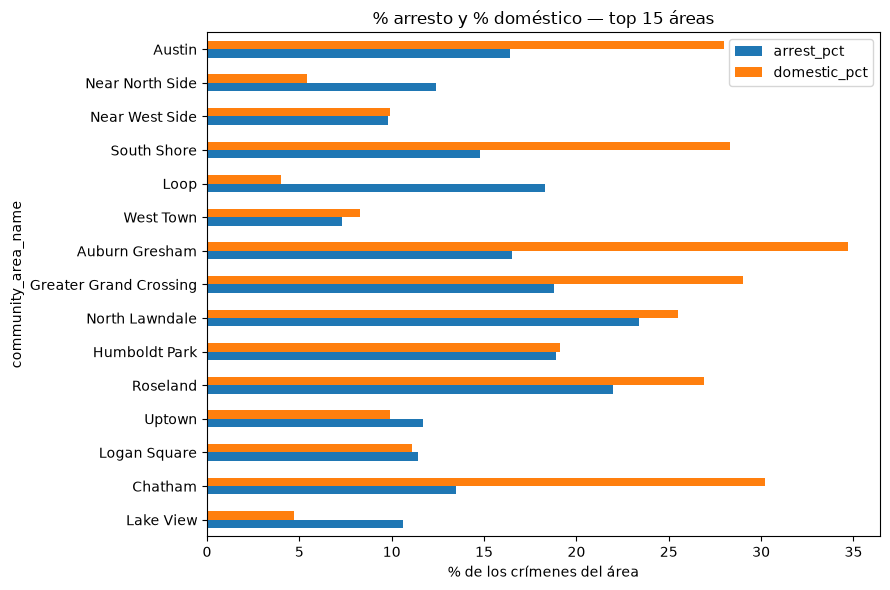

In [3]:
summary = q("""
SELECT community_area_name,
       crime_count,
       round(100.0 * arrest_count   / crime_count, 1) AS arrest_pct,
       round(100.0 * domestic_count / crime_count, 1) AS domestic_pct
FROM warehouse.vw_area_summary
ORDER BY crime_count DESC
LIMIT 15
""")
display(summary)

ax = summary.sort_values("crime_count").plot.barh(
    x="community_area_name", y=["arrest_pct", "domestic_pct"], figsize=(9, 6),
    title="% arresto y % doméstico — top 15 áreas")
ax.set_xlabel("% de los crímenes del área")
plt.tight_layout()


## 3 · Nube de coordenadas (lat / lon)

Cada punto es un crimen con coordenadas válidas (staging ya descartó (0,0)
y fuera de rango). Color = hubo arresto. Con ~1 mes ya se intuye la forma
de la ciudad y los corredores densos.


19,552 de 19,642 filas con coordenadas (99.5%)


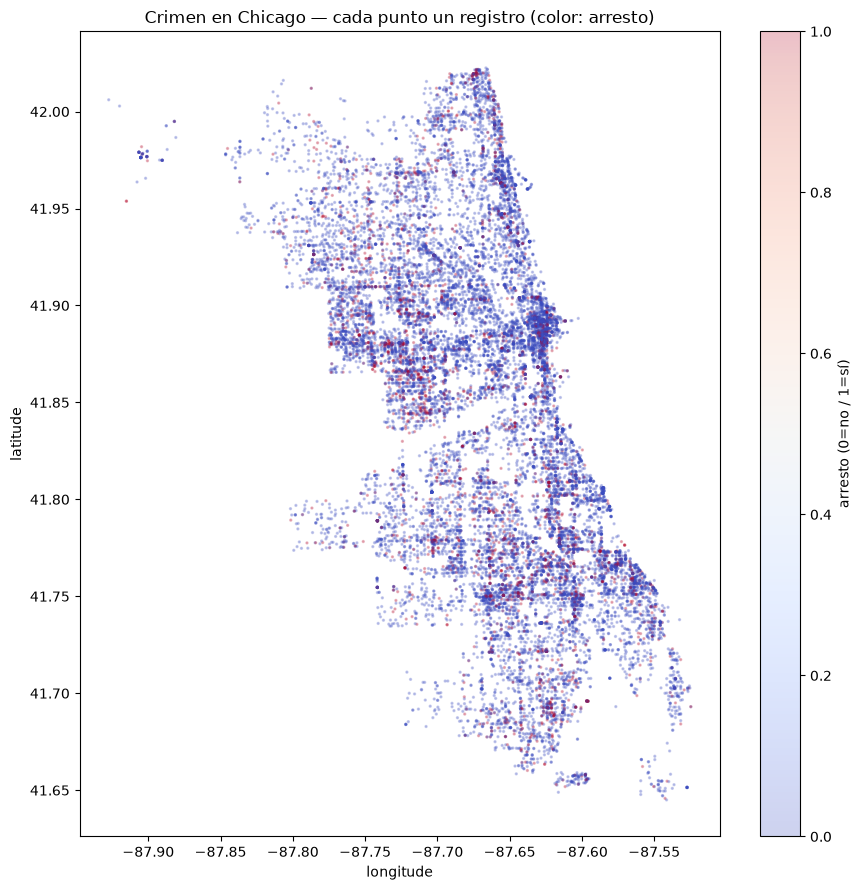

In [4]:
geo = q("""
SELECT latitude, longitude, arrest
FROM staging.crimes
WHERE latitude IS NOT NULL AND longitude IS NOT NULL
""")
total = q("SELECT count(*) AS n FROM staging.crimes").iloc[0, 0]
print(f"{len(geo):,} de {total:,} filas con coordenadas "
      f"({100*len(geo)/total:.1f}%)")

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(geo.longitude, geo.latitude, c=geo.arrest.astype(int),
                cmap="coolwarm", s=2, alpha=0.25)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Crimen en Chicago — cada punto un registro (color: arresto)")
fig.colorbar(sc, ax=ax, label="arresto (0=no / 1=sí)")
plt.tight_layout()


## 4 · Tipo de crimen × community area (heatmap)

Top 6 tipos × top 12 áreas. Muestra la *composición* del crimen por zona
(p.ej. THEFT domina en Loop/Near North — comercial; BATTERY pesa más en
áreas residenciales).


tipo,ASSAULT,BATTERY,CRIMINAL DAMAGE,MOTOR VEHICLE THEFT,OTHER OFFENSE,THEFT
area,,,,,,
Austin,100,219,103,83,57,111
Near North Side,60,113,52,39,18,362
Near West Side,60,129,117,62,31,225
South Shore,82,167,84,55,43,113
Loop,40,93,50,37,16,252
West Town,39,64,90,93,19,159
Auburn Gresham,78,124,79,40,45,92
Greater Grand Crossing,68,126,52,28,49,79
North Lawndale,71,116,48,25,27,67


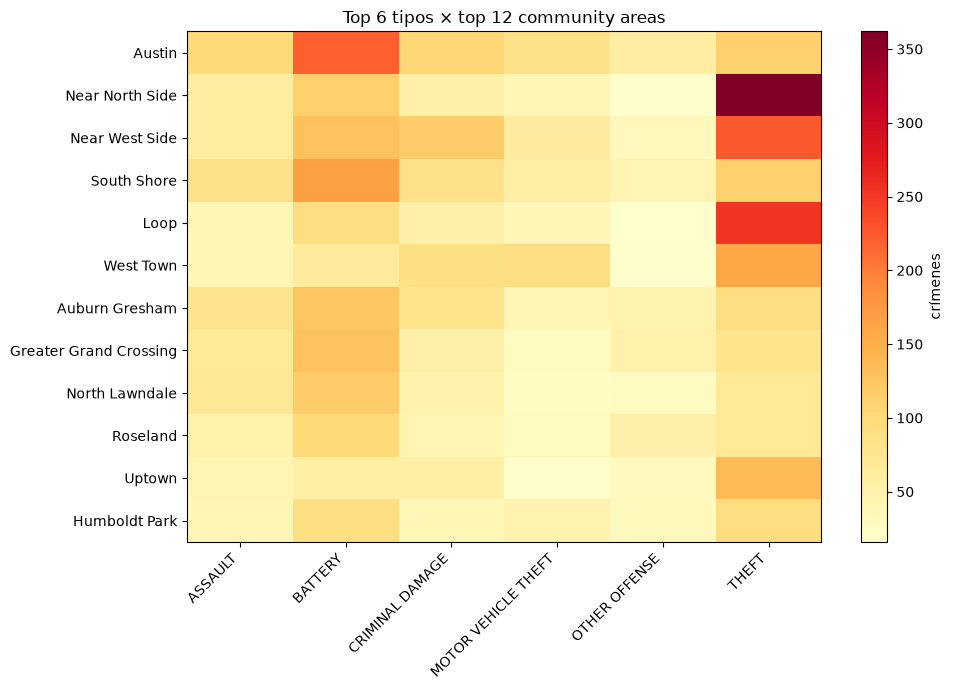

In [7]:
TOP_A, TOP_T = 12, 6
heat = q(f"""
WITH top_areas AS (
    SELECT community_area FROM warehouse.vw_area_crime_ranking
    ORDER BY crime_count DESC LIMIT {TOP_A}
), top_types AS (
    SELECT primary_type FROM staging.crimes
    WHERE primary_type IS NOT NULL
    GROUP BY primary_type ORDER BY count(*) DESC LIMIT {TOP_T}
)
SELECT a.community_area_name AS area, s.primary_type AS tipo, count(*) AS n
FROM staging.crimes s
JOIN top_areas ta ON ta.community_area = s.community_area
JOIN top_types tt ON tt.primary_type   = s.primary_type
JOIN warehouse.dim_community_area a ON a.community_area = s.community_area
GROUP BY 1, 2
""")
mat = heat.pivot_table(index="area", columns="tipo", values="n",
                       aggfunc="sum", fill_value=0)
# display(mat.sum(axis=1).sort_values(ascending=False).index)
# display(mat.loc['Austin'])
mat = mat.loc[mat.sum(axis=1).sort_values(ascending=False).index]
display(mat)

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(mat.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(mat.columns)))
ax.set_xticklabels(mat.columns, rotation=45, ha="right")
ax.set_yticks(range(len(mat.index)))
ax.set_yticklabels(mat.index)
ax.set_title(f"Top {TOP_T} tipos × top {TOP_A} community areas")
fig.colorbar(im, ax=ax, label="crímenes")
plt.tight_layout()


## 5 · Conclusiones (completar tras ver los outputs)

1. ¿Qué áreas concentran el crimen? ¿Coincide con lo esperado de Chicago
  (Loop/Near North comercial, Austin/South Shore residencial)?
2. ¿Dónde el % de arresto es más bajo pese a alto volumen? (foco operativo)
3. ¿La nube de coordenadas muestra vacíos = zonas sin geocodificación?
4. ¿El heatmap tipo×área revela firmas distintas por zona?
5. ¿Suficiente señal espacial para justificar DBSCAN de hotspots (Paso 5)?


1. Si totalmente aunque austin tiene mas concentracion de crimenes
2. Si a pesar de que hay mas crimenes ocurren menos arresto sobre en en auburn Gresham
3. si porque algunos crimenes no presentan  coordenadas 99.5%
4. Si Near North Side lidera en crimenes de THEFT
5. Si veo densidad en los datos